<a href="https://colab.research.google.com/github/Penguinboy1990/Machine-Learning/blob/main/HW4/heart_disease_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Heart Disease Classification using Decision Trees & Support Vector Machines

1) Loads the dataset into a Pandas DataFrame.

In [1]:
import pandas as pd
pd.set_option('display.max_columns', None)

df = pd.read_csv('heart_disease_uci.csv')

2. Uses inspection methods (head(), info(), and describe()) to analyze features.

In [2]:
print('\nHead Method: ')
print(df.head())

print('\nInfo Method: ')
print(df.info())

print('\nDescribe Method: ')
print(df.describe())


Head Method: 
   id  age     sex    dataset               cp  trestbps   chol    fbs  \
0   1   63    Male  Cleveland   typical angina     145.0  233.0   True   
1   2   67    Male  Cleveland     asymptomatic     160.0  286.0  False   
2   3   67    Male  Cleveland     asymptomatic     120.0  229.0  False   
3   4   37    Male  Cleveland      non-anginal     130.0  250.0  False   
4   5   41  Female  Cleveland  atypical angina     130.0  204.0  False   

          restecg  thalch  exang  oldpeak        slope   ca  \
0  lv hypertrophy   150.0  False      2.3  downsloping  0.0   
1  lv hypertrophy   108.0   True      1.5         flat  3.0   
2  lv hypertrophy   129.0   True      2.6         flat  2.0   
3          normal   187.0  False      3.5  downsloping  0.0   
4  lv hypertrophy   172.0  False      1.4    upsloping  0.0   

                thal  target  
0       fixed defect       0  
1             normal       1  
2  reversable defect       1  
3             normal       0  
4     

3. Quantify and handle any missing or implicit missing values across the columns (checking for non-standard placeholders such as ? strings) and implement a structured imputation strategy using Scikit-Learn's SimpleImputer.
4. Isolate numerical and categorical features, then build a Scikit-Learn ColumnTransformer and Pipeline that applies appropriate scaling (StandardScaler or MinMaxScaler) to numerical columns and encoding (OneHotEncoder) to categorical columns.

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score, RocCurveDisplay)
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree

print("\nMissing values before pipeline execution:")
print(df.isnull().sum())

# Binarizes the target if multi-class - "0 for no disease, and 1 or greater indicating the presence of heart disease"
X = df.drop(columns=["target"])
y = df['target'].apply(lambda x: 1 if x > 0 else 0)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=35, stratify=y)

numeric_cols = ["age", "trestbps", "chol", "thalch", "oldpeak"]

categoric_cols = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

target_col = "target"

numeric_transformer = Pipeline( steps=[('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])

categoric_transformer = Pipeline( steps = [('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])

preprocessor = ColumnTransformer( transformers=[('num', numeric_transformer, numeric_cols), ('cat', categoric_transformer, categoric_cols)])


Missing values before pipeline execution:
id            0
age           0
sex           0
dataset       0
cp            0
trestbps     59
chol         30
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
target        0
dtype: int64


5. Instantiate and train a Support Vector Classifier (SVC) configured with kernel='rbf' and probability=True within your pipeline, then evaluate performance using a confusion matrix, classification report, and ROC-AUC curve.

In [5]:
svc_pipeline = Pipeline(steps = [('preprocessor', preprocessor), ('classifier', SVC(kernel='rbf', probability=True, random_state=35))])

svc_pipeline.fit(X_train, y_train)
y_pred_svc = svc_pipeline.predict(X_test)
y_prob_svc = svc_pipeline.predict_proba(X_test)[:, 1]

print("\nSVC Classification Report")
print(classification_report(y_test, y_pred_svc))

print("\nSVC Confusion Matrix")
print(confusion_matrix(y_test, y_pred_svc))

print("SVC ROC-AUC Score:", np.round(roc_auc_score(y_test, y_prob_svc),4))



SVC Classification Report
              precision    recall  f1-score   support

           0       0.91      0.85      0.88        82
           1       0.89      0.93      0.91       102

    accuracy                           0.90       184
   macro avg       0.90      0.89      0.89       184
weighted avg       0.90      0.90      0.90       184


SVC Confusion Matrix
[[70 12]
 [ 7 95]]
SVC ROC-AUC Score: 0.9272


6. Instantiate and train a Decision Tree Classifier (DecisionTreeClassifier) within your pipeline, and evaluate its performance using identical metrics to compare against your SVC model

In [6]:
dt_pipeline = Pipeline( steps = [('preprocessor', preprocessor), ('classifier', DecisionTreeClassifier(max_depth=4, random_state=35))])

dt_pipeline.fit(X_train, y_train)
y_pred_dt = dt_pipeline.predict(X_test)
y_prob_dt = dt_pipeline.predict_proba(X_test)[:, 1]

print("\nDecision Tree Classification Report")
print(classification_report(y_test, y_pred_dt))

print("Decision Tree Confusion Matrix")
print(confusion_matrix(y_test, y_pred_dt))

print("Decision Tree ROC-AUC Score: ", np.round(roc_auc_score(y_test, y_prob_dt),4))



Decision Tree Classification Report
              precision    recall  f1-score   support

           0       0.72      0.89      0.80        82
           1       0.89      0.73      0.80       102

    accuracy                           0.80       184
   macro avg       0.81      0.81      0.80       184
weighted avg       0.82      0.80      0.80       184

Decision Tree Confusion Matrix
[[73  9]
 [28 74]]
Decision Tree ROC-AUC Score:  0.8701


7. Perform hyperparameter tuning using GridSearchCV on your SVC pipeline (exploring parameters such as C and gamma) to optimize cross-validation performance.

In [7]:
param_grid = {'classifier__C': [0.1, 1, 10, 100], 'classifier__gamma': ['scale', 'auto', 0.01, 0.1, 1]}

grid_search = GridSearchCV(estimator=svc_pipeline, param_grid=param_grid, cv=5, scoring='roc_auc', n_jobs=-1)
grid_search.fit(X_train, y_train)

print("\nBest Parameters for SVC:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Score for SVC:")
print(grid_search.best_score_)

best_svc = grid_search.best_estimator_
y_prob_best_svc = best_svc.predict_proba(X_test)[:, 1]
print("Optimized Test ROC-AUC Score:", np.round(roc_auc_score(y_test, y_prob_best_svc),4))


Best Parameters for SVC:
{'classifier__C': 1, 'classifier__gamma': 'scale'}

Best Cross-Validation Score for SVC:
0.8867685541398277
Optimized Test ROC-AUC Score: 0.9272


8. Generate a decision tree visualization (plot_tree) or inspect feature importances to interpret how the model separates patients with heart disease from healthy patients.

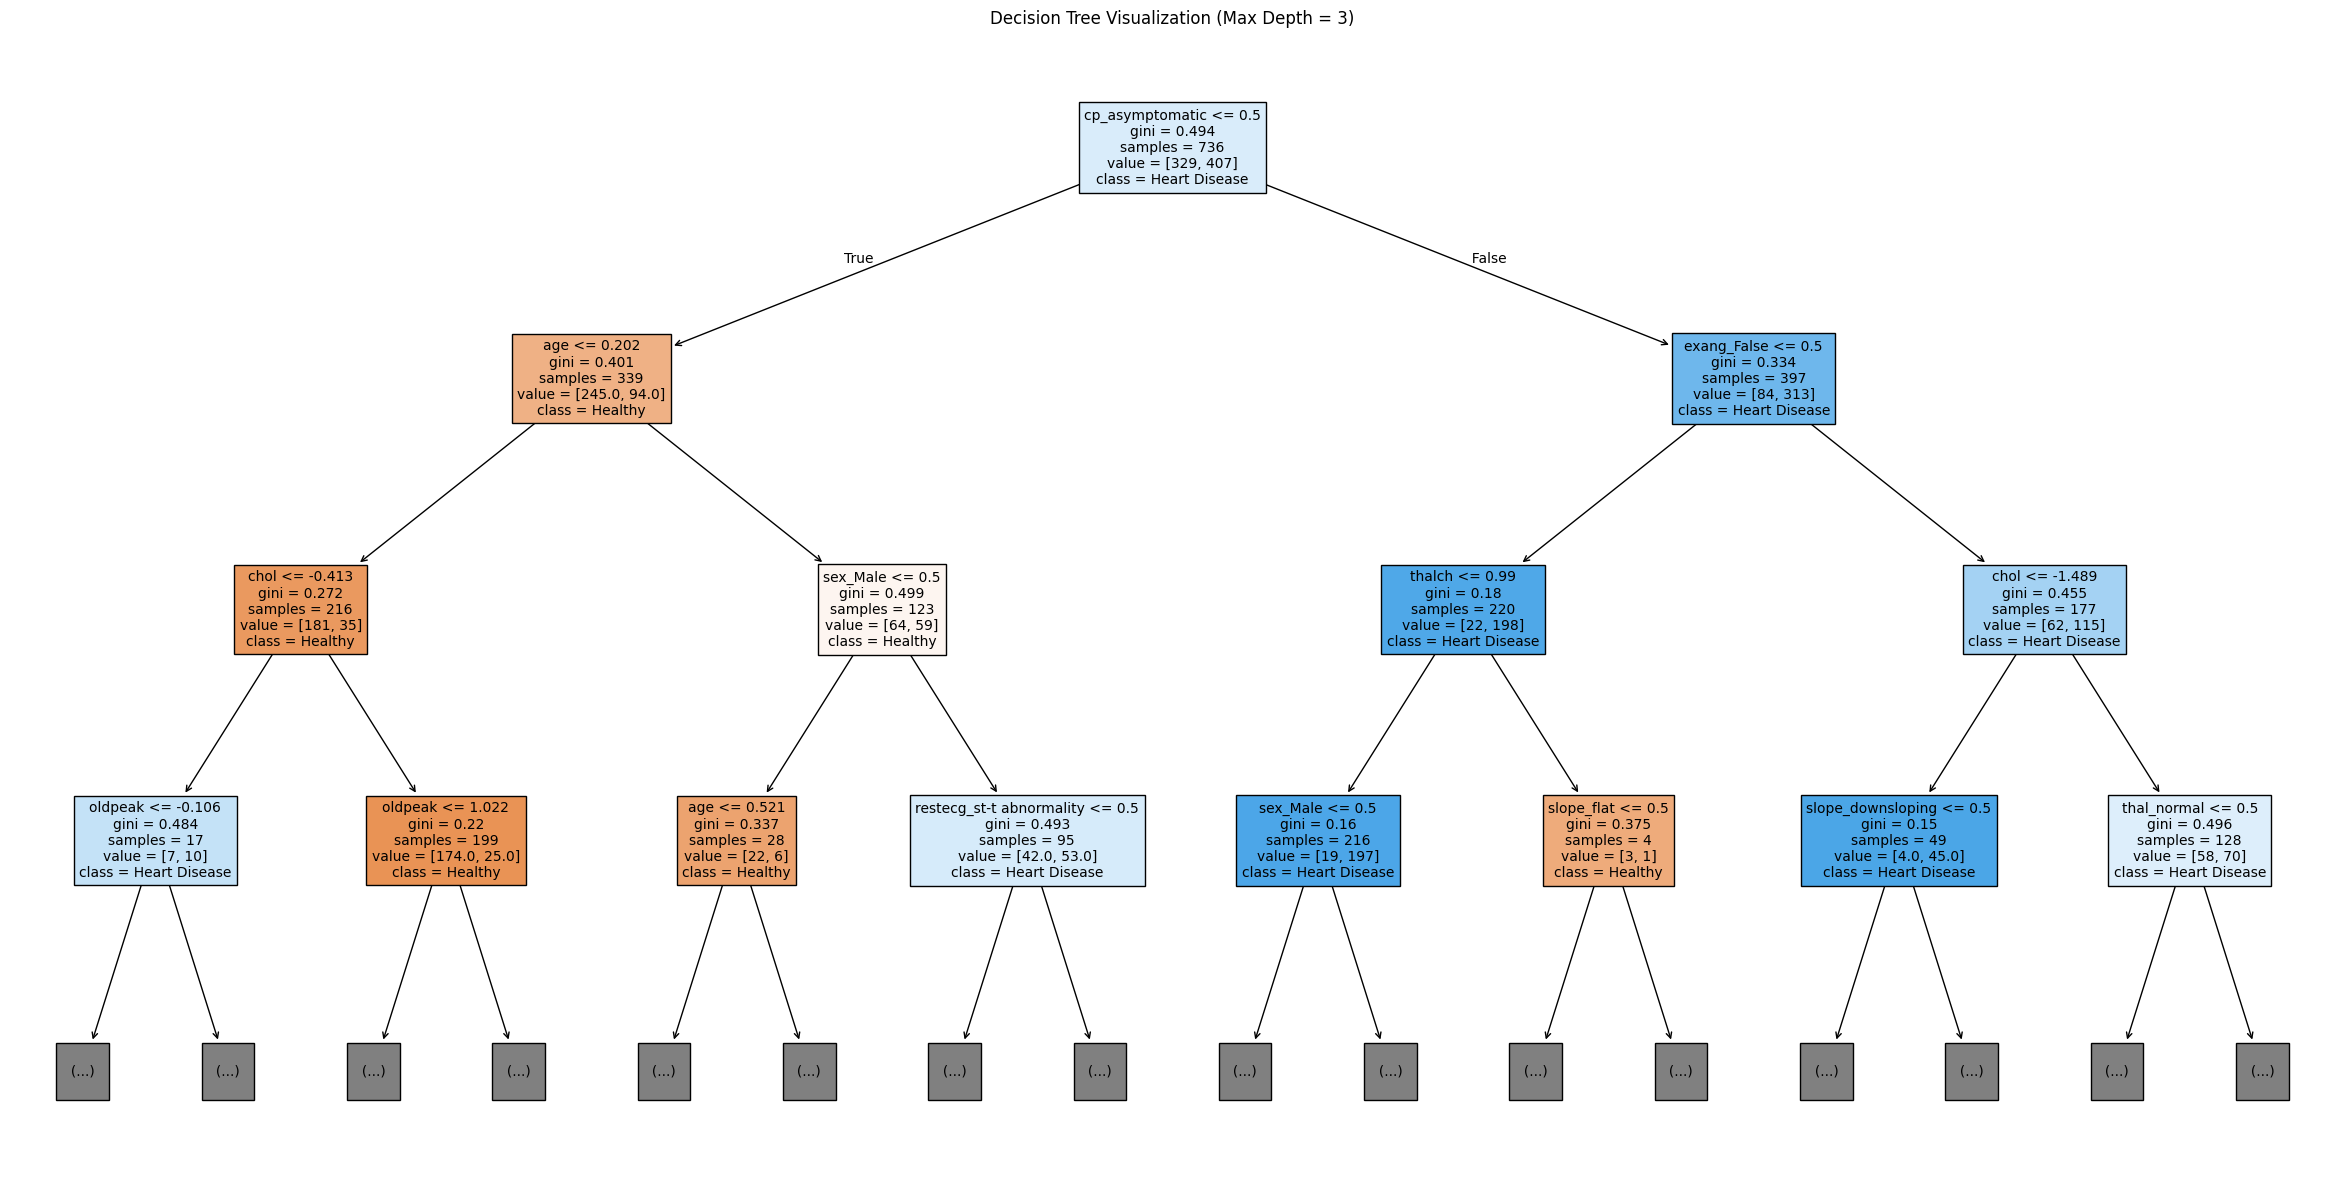

In [8]:
cat_encoder = dt_pipeline.named_steps['preprocessor'].named_transformers_['cat'].named_steps['onehot']
encoded_cat_cols = cat_encoder.get_feature_names_out(categoric_cols).tolist()
all_feature_names = numeric_cols + encoded_cat_cols

plt.figure(figsize=(30, 15))
plot_tree(dt_pipeline.named_steps['classifier'], feature_names=all_feature_names, class_names=['Healthy', 'Heart Disease'], filled=True, max_depth=3, fontsize=10)
plt.title("Decision Tree Visualization (Max Depth = 3)")
plt.show()

